# **Section 3: Advanced data exploration and feature selection**

In this notebook, we will perform feature selection to reduce the number of features in our data set. We will decide which features to keep based on the **training data** only to prevent data leakage. The selected features are then applied to test data. We will select features according to the following strategies:

- **Remove features with little variance**. First of all, we will remove features with very little variance as they do not provide information useful for a machine learning classification problem: SVs present in only one or a few training samples.
- **Selecting features associated with resistance (using SelectKBest)**. We will use SelectKBest from scikit learn to keep only the most discriminative features. We will use a Chi2 score and keep all features significantly associated to resistance profile.
- **Grouping identical features**. SVs that are present in exactly the same samples carry the same information. We keep one feature per group (a "cluster") and save which SVs belong to each cluster for the biomarker analysis.

#### **Contents:**
1. **Load the data**


2. **Remove near-constant features**
   - 2.1. Visualizing variance for all features
   - 2.2. Removing low variance features


3. **Select top features using SelectKBest**


4. **Removing duplicated features**


5. **Save selected feature matrix**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import SelectKBest, chi2
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
import warnings
warnings.filterwarnings('ignore')

# Set styles
sns.set_style('whitegrid')
sns.set_palette('pastel')

## **1. Load Data**

In [2]:
# Load training features and labels
sv_train = pd.read_csv('Data/sv_train.csv', index_col=0)
sv_test = pd.read_csv("Data/sv_test.csv", index_col=0)
sxt_train = pd.read_csv('Data/SXT_train.csv', index_col=0)
sxt_test = pd.read_csv("Data/SXT_test.csv", index_col=0)

# Information about each SV (type, length)
sv_meta = pd.read_csv('Data/svs_core_meta.tsv', sep='\t', index_col=0)

print(f'Training set shape: {sv_train.shape}')
print(f'Labels shape: {sxt_train.shape}')
print(f'Resistance distribution:')
print(sxt_train.value_counts())

Training set shape: (177, 3501)
Labels shape: (177, 1)
Resistance distribution:
SXT_binary
1             103
0              74
Name: count, dtype: int64


## **2. Remove near-constant features**
Let's now remove features that have very little variance (that are almost the same for all samples). Let's choose which features to remove on the training set and then remove the same features from the test set.

Binary features follow a Bernoulli distribution, with variance var = p(1-p) with p the fraction of samples equal to 1. So for instance, the variance will be equivalent to 0.16 if 80% of the samples are equal to 1 (var = 0.8*0.2 = 0.16). For perfectly balanced features, the variance is equal to 0.25. We will calculate the variance for all features and remove features with little variance.

### **2.1 Visualizing the variance for all features**
Let's first visualize the variance for all of our features using a histogram.

In [3]:
p = sv_train.mean(axis=0)
variance = p * (1 - p)

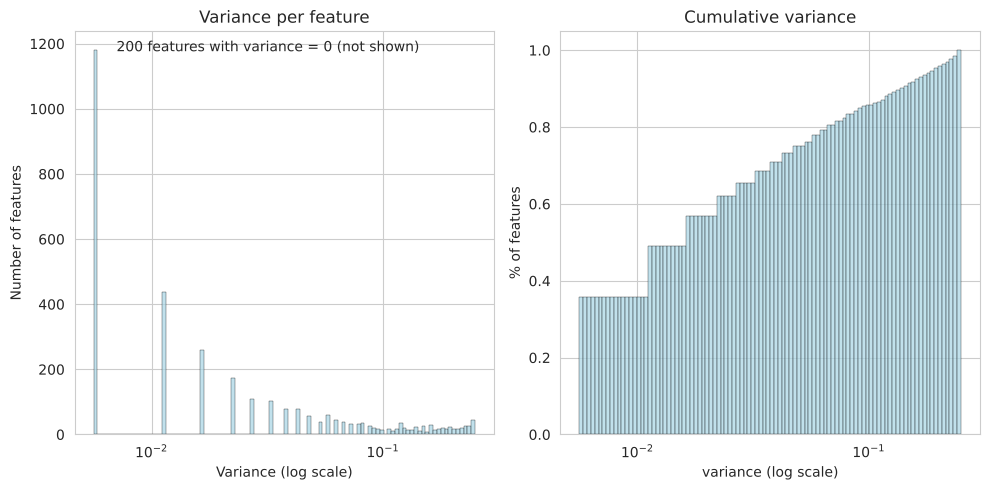

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

n_zeros = (variance == 0).sum()
var_nonzero = variance[variance > 0]

sns.histplot(var_nonzero, bins=100, log_scale=True, color='lightblue', edgecolor='black', ax=axes[0])
axes[0].set_title("Variance per feature")
axes[0].set_xlabel("Variance (log scale)")
axes[0].set_ylabel("Number of features")
axes[0].text(0.1, 0.95, f"{n_zeros} features with variance = 0 (not shown)", transform=axes[0].transAxes)

sns.histplot(var_nonzero, bins=100, log_scale=True, color='lightblue', edgecolor='black', ax=axes[1], cumulative=True, stat="density")
axes[1].set_title("Cumulative variance")
axes[1].set_xlabel("variance (log scale)")
axes[1].set_ylabel("% of features")

plt.tight_layout()
plt.savefig('Figures/03_Std.png', dpi=300, bbox_inches='tight')
plt.show()

Features with variance 0 are SVs that are present in all or none of the **training** samples (the pipeline only removed SVs that are constant over all samples). As for the SNPs, I will remove all features with a variance smaller than 0.015, which corresponds to SVs carried by fewer than about 1.5% of the training samples (or by more than about 98.5% of them).

### **2.2 Removing low variance features**

In [5]:
low_variance_mask = variance < 0.015
print(f'{low_variance_mask.sum()} features have low variance')

1818 features have low variance


In [6]:
print(f'Before removing features: {sv_train.shape}')
sv_train = sv_train.loc[:,~low_variance_mask]

print(f'After removing features: {sv_train.shape}')

Before removing features: (177, 3501)
After removing features: (177, 1683)


In [7]:
print(f'Before removing features: {sv_test.shape}')
sv_test = sv_test.loc[:, ~low_variance_mask]
print(f'After removing features: {sv_test.shape}')

Before removing features: (50, 3501)
After removing features: (50, 1683)


## **3. Select Features using SelectKBest**

I will now select features using SelectKBest and a Chi2 score. This identifies the most discriminative features. I will choose to keep only features that are significantly associated with the resistance profile of our samples (Benjamini-Hochberg adjusted p-value < 0.05).

### **3.1 Score all features**

In [8]:
from scipy.stats import false_discovery_control

# Calculate Chi2 for all features
selector = SelectKBest(score_func=chi2, k='all')
selector.fit(sv_train, sxt_train.iloc[:, 0])

feature_importance = pd.DataFrame({
    'feature': sv_train.columns,
    'chi2': selector.scores_,
    'p_value': selector.pvalues_,
})

feature_importance['p_adj'] = false_discovery_control(feature_importance['p_value'], method='bh')
feature_importance = feature_importance.sort_values('chi2', ascending=False)

significant = feature_importance['p_adj'] < 0.05
print(f"Significant features: {significant.sum()} ({significant.mean() * 100:.1f}%)")

Significant features: 9 (0.5%)


### **3.2 Select the best features**
Almost none of the features is significantly associated with resistance on its own once the
p-values are corrected for multiple testing, so selecting on significance leaves the models
with almost nothing to work with. Instead of that, we keep a fixed number of features: the
200 with the highest chi2 score. This is a ranking and not a test, so these features are not
claimed to be individually significant; the number that would have passed the threshold is
printed for information.

In [9]:
N_FEATURES = 200

# Almost no feature is significant on its own after correcting for multiple testing, so
# instead of selecting on significance we keep a fixed number of features: the N_FEATURES
# best ones by chi2 score. The number that would have been significant is reported for
# information.
n_significant = int((feature_importance['p_adj'] < 0.05).sum())
sig_features = feature_importance['feature'].head(N_FEATURES)

print(f'{n_significant} features have a BH-adjusted p-value < 0.05')
print(f'Keeping the top {len(sig_features)} features by chi2 score')

sv_train_selected = sv_train[sig_features]
sv_test_selected = sv_test[sig_features]
print(f'Features before selection: {sv_train.shape[1]}')
print(f'Features after selection: {sv_train_selected.shape[1]}')


9 features have a BH-adjusted p-value < 0.05
Keeping the top 200 features by chi2 score
Features before selection: 1683
Features after selection: 200


In [10]:
# SV types among the selected features, compared to all features after the variance filter
type_comparison = pd.DataFrame({
    'after variance filter': sv_meta.loc[sv_train.columns, 'svtype'].value_counts(normalize=True),
    'selected': sv_meta.loc[sig_features, 'svtype'].value_counts(normalize=True),
}).fillna(0)
print((type_comparison * 100).round(1))

        after variance filter  selected
svtype                                 
DEL                      42.4      51.5
DUP                       8.0       7.5
INV                      49.6      41.0


### **3.3 SVs per feature (training set)**
Let's visualize in how many samples each of the remaining features is present, for the training set.

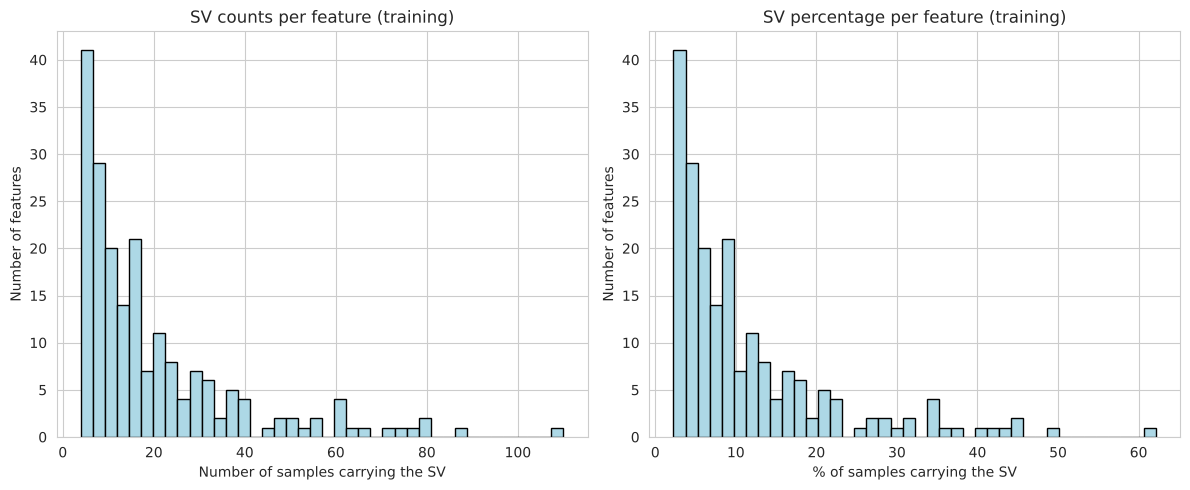

In [11]:
counts_regions = sv_train_selected.sum(axis=0)
percentage_regions = sv_train_selected.mean(axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(counts_regions, bins=40, color='lightblue', edgecolor='black')
axes[0].set_xlabel('Number of samples carrying the SV')
axes[0].set_ylabel('Number of features')
axes[0].set_title('SV counts per feature (training)')

axes[1].hist(percentage_regions, bins=40, color='lightblue', edgecolor='black')
axes[1].set_xlabel('% of samples carrying the SV')
axes[1].set_ylabel('Number of features')
axes[1].set_title('SV percentage per feature (training)')

plt.tight_layout()
plt.savefig('Figures/03_SVs_per_feature_train.png', dpi=300, bbox_inches='tight')
plt.show()

After feature selection, there should be no features left that are present in 0% or 100% of the training samples. Let's also quickly see what happens in the test set.

### **3.4 SVs per feature (test set)**

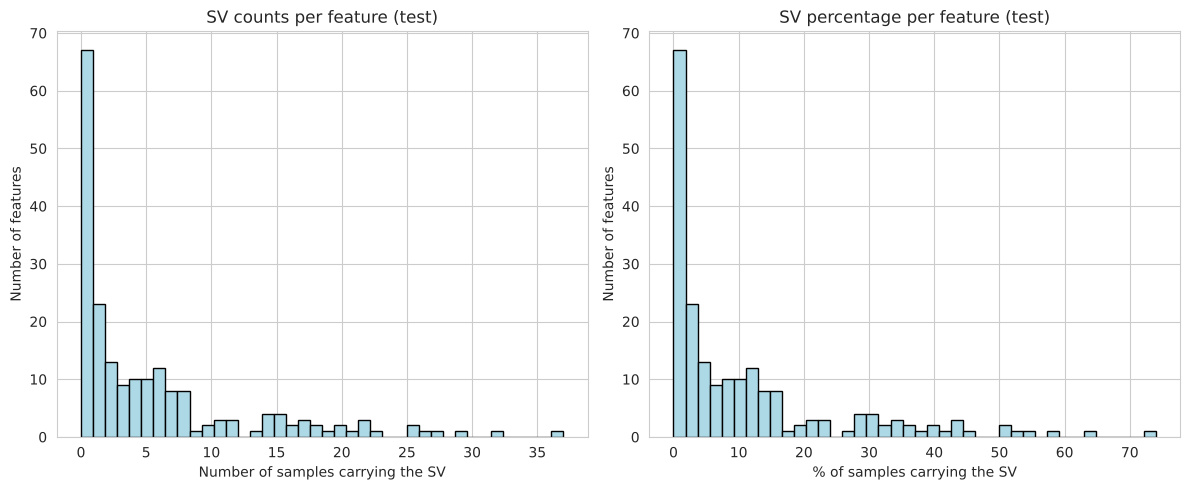

In [12]:
counts_regions = sv_test_selected.sum(axis=0)
percentage_regions = sv_test_selected.mean(axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(counts_regions, bins=40, color='lightblue', edgecolor='black')
axes[0].set_xlabel('Number of samples carrying the SV')
axes[0].set_ylabel('Number of features')
axes[0].set_title('SV counts per feature (test)')

axes[1].hist(percentage_regions, bins=40, color='lightblue', edgecolor='black')
axes[1].set_xlabel('% of samples carrying the SV')
axes[1].set_ylabel('Number of features')
axes[1].set_title('SV percentage per feature (test)')

plt.tight_layout()
plt.savefig('Figures/03_SVs_per_feature_test.png', dpi=300, bbox_inches='tight')
plt.show()

In the test set, some features can be absent from all samples: they were kept because they vary in the training set. It will be interesting to see how well the models perform on this test set, which belongs to different lineages than the training set.

## **4. Removing duplicated features**
Finally, we will remove identical features by keeping only one of them. We will however save which original features were removed for downstream biomarker analysis.

### **4.1 Identifying duplicates**
Let's first identify duplicated features and keep only the first one.

In [13]:
# Find identical columns and create a single cluster per unique presence/absence pattern
_, first_idx, labels = np.unique(
    sv_train_selected.to_numpy(), axis=1, return_index=True, return_inverse=True
)
labels = labels.ravel()                 # cluster number for every SV
new_features = sv_train_selected.columns[first_idx]

print(f"We go from {sv_train_selected.shape[1]} features to {len(new_features)} features")

We go from 200 features to 199 features


### **4.2 Create new clusters**
Let's now create the clusters and save the information about which SV went into each newly created cluster, together with the type and length of each SV.

In [14]:
# Saving which SV went into which cluster
clusters = pd.DataFrame({
    "cluster": labels,
    "feature": sv_train_selected.columns,
})

clusters["cluster_size"] = clusters["cluster"].map(clusters["cluster"].value_counts())
clusters = clusters.join(sv_meta[['svtype', 'svlen']], on='feature')
clusters = clusters.sort_values(["cluster", "feature"])
clusters.to_csv("Data/clusters.csv", index=False)

print(f'{(clusters.groupby("cluster").size() > 1).sum()} clusters were made from more than one SV')

1 clusters were made from more than one SV


Finally, let's reduce the size of the feature matrix to contain only the newly created clusters. Cluster number i is the i-th unique presence/absence pattern, which is also the column order of new_features, so the column names match the cluster numbers in Data/clusters.csv.

In [15]:
col_names = range(len(new_features))
sv_train_reduced = sv_train_selected[new_features]
sv_train_reduced.columns = col_names

sv_test_reduced = sv_test_selected[new_features]
sv_test_reduced.columns = col_names

### **4.3 SVs per feature (training set)**

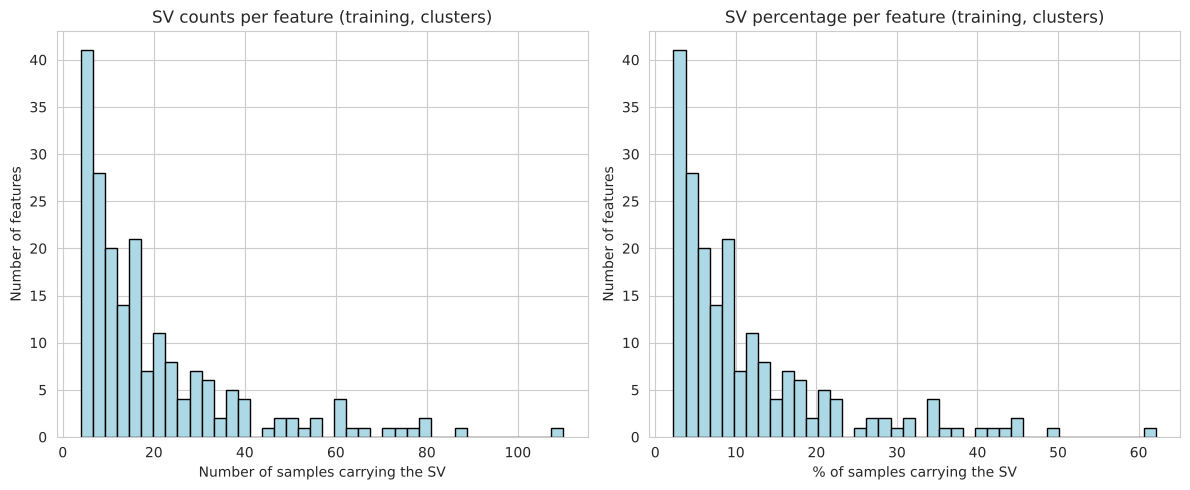

In [16]:
counts_regions = sv_train_reduced.sum(axis=0)
percentage_regions = sv_train_reduced.mean(axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(counts_regions, bins=40, color='lightblue', edgecolor='black')
axes[0].set_xlabel('Number of samples carrying the SV')
axes[0].set_ylabel('Number of features')
axes[0].set_title('SV counts per feature (training, clusters)')

axes[1].hist(percentage_regions, bins=40, color='lightblue', edgecolor='black')
axes[1].set_xlabel('% of samples carrying the SV')
axes[1].set_ylabel('Number of features')
axes[1].set_title('SV percentage per feature (training, clusters)')

plt.tight_layout()
plt.savefig('Figures/03_SVs_per_feature_train_reduced.png', dpi=300, bbox_inches='tight')
plt.show()

### **4.4 SVs per feature (test set)**

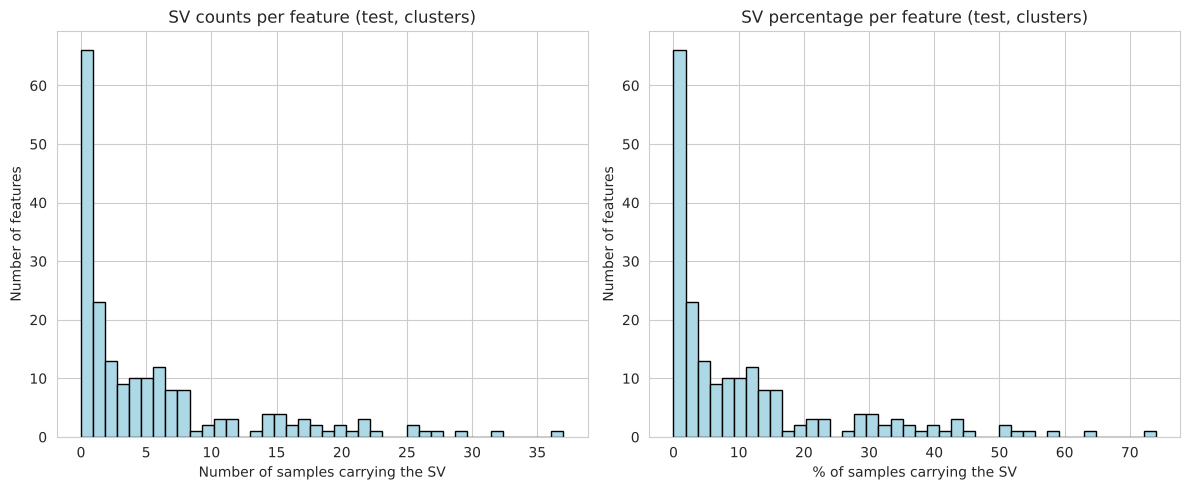

In [17]:
counts_regions = sv_test_reduced.sum(axis=0)
percentage_regions = sv_test_reduced.mean(axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(counts_regions, bins=40, color='lightblue', edgecolor='black')
axes[0].set_xlabel('Number of samples carrying the SV')
axes[0].set_ylabel('Number of features')
axes[0].set_title('SV counts per feature (test, clusters)')

axes[1].hist(percentage_regions, bins=40, color='lightblue', edgecolor='black')
axes[1].set_xlabel('% of samples carrying the SV')
axes[1].set_ylabel('Number of features')
axes[1].set_title('SV percentage per feature (test, clusters)')

plt.tight_layout()
plt.savefig('Figures/03_SVs_per_feature_test_reduced.png', dpi=300, bbox_inches='tight')
plt.show()

### **4.5 Dendrogram**
Finally, let's repeat the analysis we did in the first notebook to see how our strains cluster together taking these new features into account, and how this relates to their resistance profile.

In [18]:
X = sv_train_reduced.values
dist = X @ (1 - X).T + (1 - X) @ X.T
dist_df = pd.DataFrame(dist, index=sv_train_reduced.index, columns=sv_train_reduced.index)

In [19]:
Z = linkage(squareform(dist_df.values, checks=False), method="average")

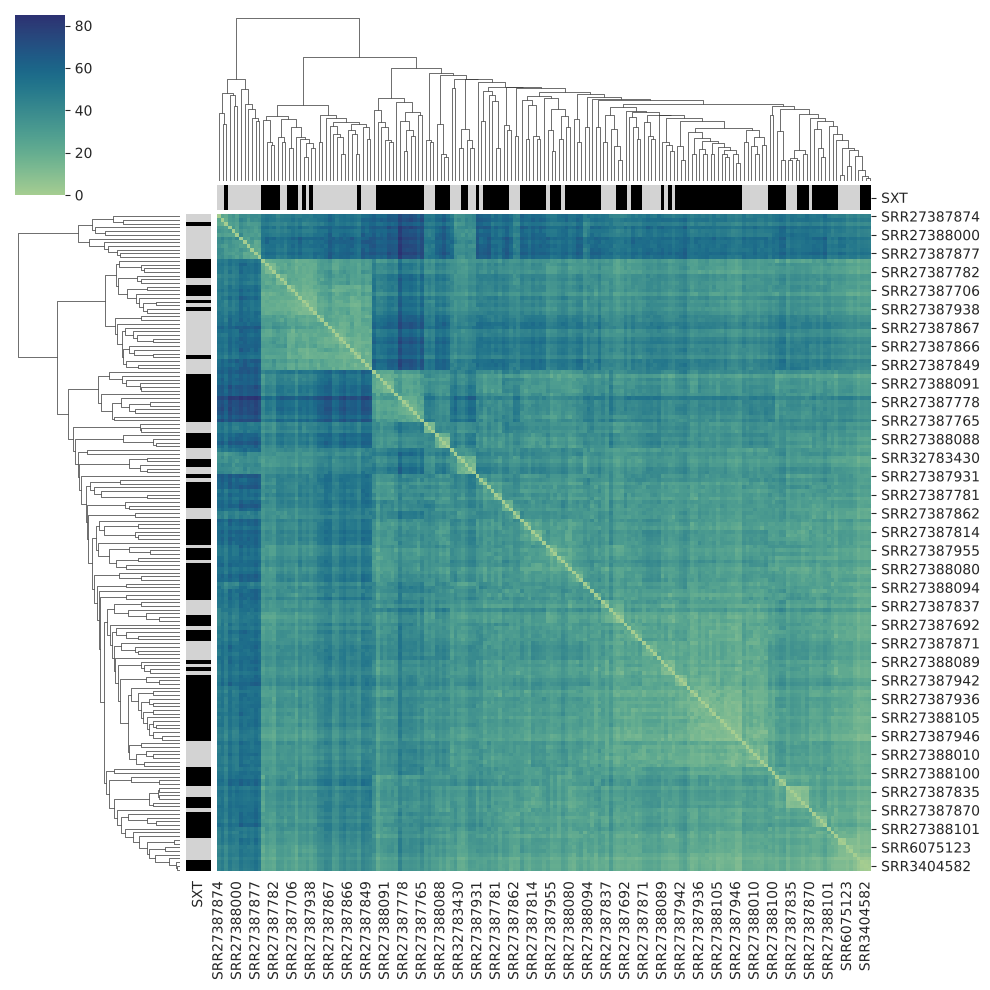

In [20]:
palette = {0: "lightgrey", 1: "black"}
strain_colors = sxt_train.iloc[:, 0].map(palette).rename("SXT")

sns.clustermap(dist_df, cmap="crest", row_linkage=Z, col_linkage=Z, row_colors=strain_colors, col_colors=strain_colors)

plt.savefig('Figures/03_Clustering.png', dpi=600, bbox_inches='tight')
plt.show()

If strains with the same resistance profile now cluster together more than in notebook 1, the selected features look promising for a machine learning approach.

## **5. Save Selected Features**

In [21]:
# Save selected training features
sv_train_reduced.to_csv('Data/sv_train_selected.csv')
sxt_train.to_csv("Data/SXT_train_selected.csv")

# Save selected test features
sv_test_reduced.to_csv('Data/sv_test_selected.csv')
sxt_test.to_csv("Data/SXT_test_selected.csv")

In [22]:
print(f'Final training data shape: {sv_train_reduced.shape}')
print(f'Final test data shape: {sv_test_reduced.shape}')

print(f'Final training label shape: {sxt_train.shape}')
print(f'Final test label shape: {sxt_test.shape}')

Final training data shape: (177, 199)
Final test data shape: (50, 199)
Final training label shape: (177, 1)
Final test label shape: (50, 1)
